In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from simulate_bounds import EPS_INTERVAL

from rayfish.classical_fisher_information.measurement_basis.hermite_gaussian_basis import (  # noqa: E501
    _mix_modes_via_unitary,
    measurement_basis,
)
from visualize_helpers import (
    create_fig_and_ax,
    latexify,
    plot_individual_fi,
    plot_mode_mixing_sweep,
)

latexify()
FORMAT = "pdf"
continuous_cmaps = [
    "Greens",
    "Reds",
    "Purples",
    "Oranges",
    "viridis",
    "plasma",
    "cividis",
    "magma",
    "inferno",
    "turbo",
    "pink",
    "bone",
    "gray",
    "copper",
    "Blues",
]

In [ ]:
%matplotlib inline

# Mode leakage

In [ ]:
md = 4
fig, _ = plot_mode_mixing_sweep(
    measurement_basis(md),
    [0.0, 0.1, 0.3, 0.6, 1.0],
    _mix_modes_via_unitary,
    mode_degree=md,
    mode_indices=[
        i * md + j for (i, j) in [(0, 0), (0, 1), (0, 2), (0, 3), (2, 0), (2, 2)]
    ],
)

In [ ]:
coords = np.load("coordinates.npy")
p_range = -coords[0, :, 6]
x_range = coords[:, 0, 2]

fis = []
fis_inv = []
for mixing_eps in EPS_INTERVAL:
    fis.append(np.load(f"mixed_fi_ms_eps_{mixing_eps}.npy"))
    fis_inv.append(np.load(f"mixed_fi_ms_inv_{mixing_eps}.npy"))

In [ ]:
def eps_to_db(eps: float) -> float:
    """Convert eps to DB."""
    return 20 * np.log10(np.sin(eps)) if eps > 0 else -np.inf

# s param

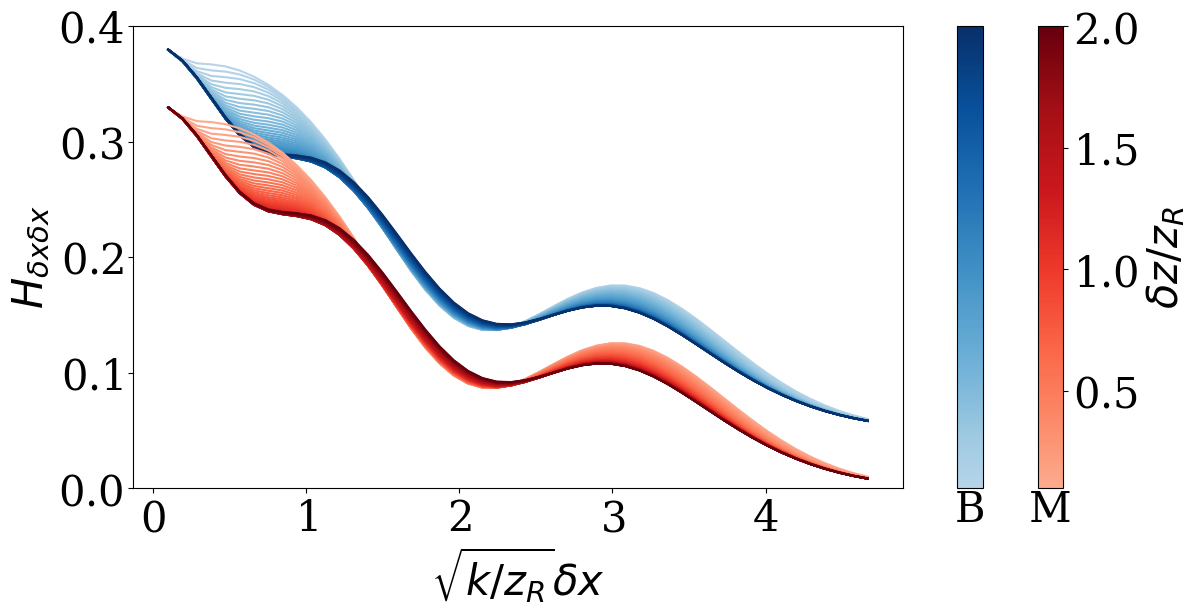

In [ ]:
fig, axs = create_fig_and_ax(len(fis))
for i, fi in enumerate(fis):
    ms_cm_baseline = plot_individual_fi(
        fig,
        axs,
        np.sum(fi, axis=2)[:, :, 0, 0],
        x_range,
        p_range,
        continuous_cmaps[i],
        i + 1,
        f"DB:{eps_to_db(EPS_INTERVALl[i])}",
    )


axs[0].set_ylim(0, 0.4)
axs[len(fis)].set_ylabel(r"$\delta z / z_R$")
axs[0].set_xlabel(r"$\sqrt{k/z_R} \delta x$")
axs[0].set_ylabel(r"$H_{\delta x \delta x}$")

# fig.savefig(f"s_param_fi_comparison.{FORMAT}", format=FORMAT, bbox_inches="tight")
plt.show()

In [16]:
# Whitelist of continuous colormaps suitable for publication
continuous_cmaps = [
    "Greens",
    "Reds",
    "Purples",
    "Oranges",
    "viridis",
    "plasma",
    "cividis",
    "magma",
    "inferno",
    "turbo",
    "pink",
    "bone",
    "gray",
    "copper",
    "Blues",
]


def filter_pub_friendly_continuous(
    max_rgb: float = 1, sample_points: int = 256
) -> list:
    """Good colors for plots."""
    good_cmaps = []
    for name in continuous_cmaps:
        cmap = plt.get_cmap(name)
        colors = cmap(np.linspace(0, 1, sample_points))[:, :3]  # RGB only
        if np.any(colors > max_rgb):
            continue  # skip overly bright colors
        good_cmaps.append(name)
    return good_cmaps

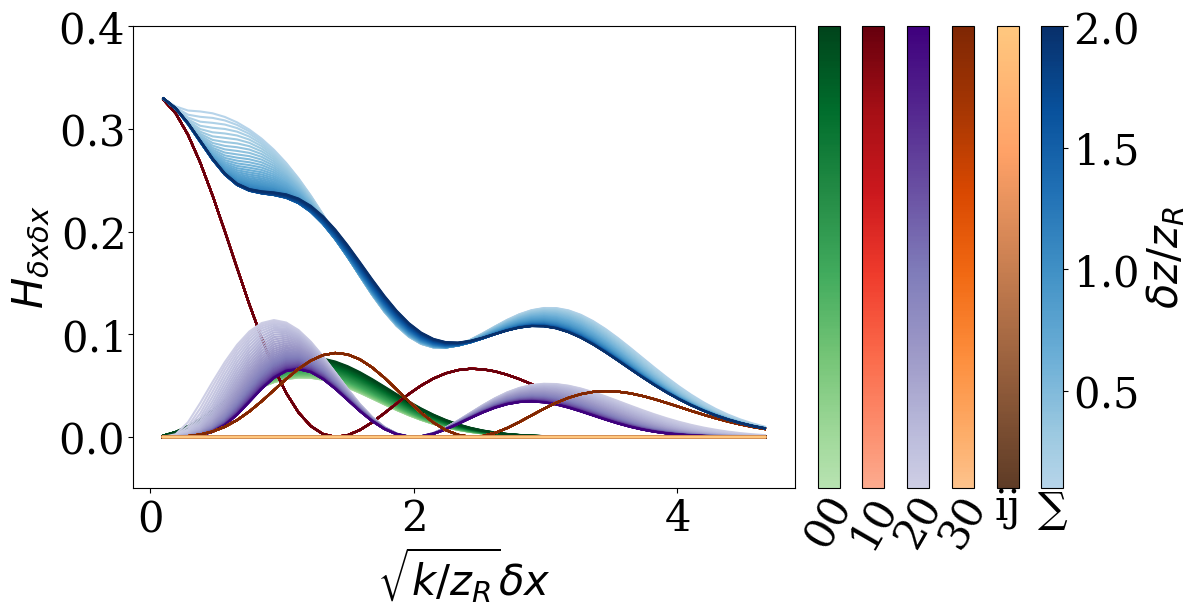

In [17]:
n_modes = fi_ms_.shape[2]
good_cmaps = filter_pub_friendly_continuous()

n_axes = 5
fig, axs = create_fig_and_ax(n_axes + 1)

counter = 0
for i in range(mode_degree):
    for j in range(mode_degree):
        if j != 0:
            plot_individual_fi(
                fig,
                axs,
                fi_ms_[:, :, i * mode_degree + j, 0, 0],
                x_range,
                p_range,
                good_cmaps[-2],
                n_axes,
                r"ij",
            )
        else:
            plot_individual_fi(
                fig,
                axs,
                fi_ms_[:, :, i * mode_degree + j, 0, 0],
                x_range,
                p_range,
                good_cmaps[counter],
                counter + 1,
                f"{i}{j}",
                rotation=60,
            )

            counter += 1

sum_cm = plot_individual_fi(
    fig,
    axs,
    np.sum(fi_ms_, axis=2)[:, :, 0, 0],
    x_range,
    p_range,
    good_cmaps[-1],
    n_axes + 1,
    "∑",
    False,
)


axs[0].set_ylim(-0.05, 0.4)
axs[n_axes + 1].set_ylabel(r"$\delta z / z_R$")
axs[0].set_xlabel(r"$\sqrt{k/z_R} \delta x$")
axs[0].set_ylabel(r"$H_{\delta x \delta x}$")

fig.savefig(
    f"s_param_individual_mode_contributions.{FORMAT}",
    format=FORMAT,
    bbox_inches="tight",
)
plt.show()

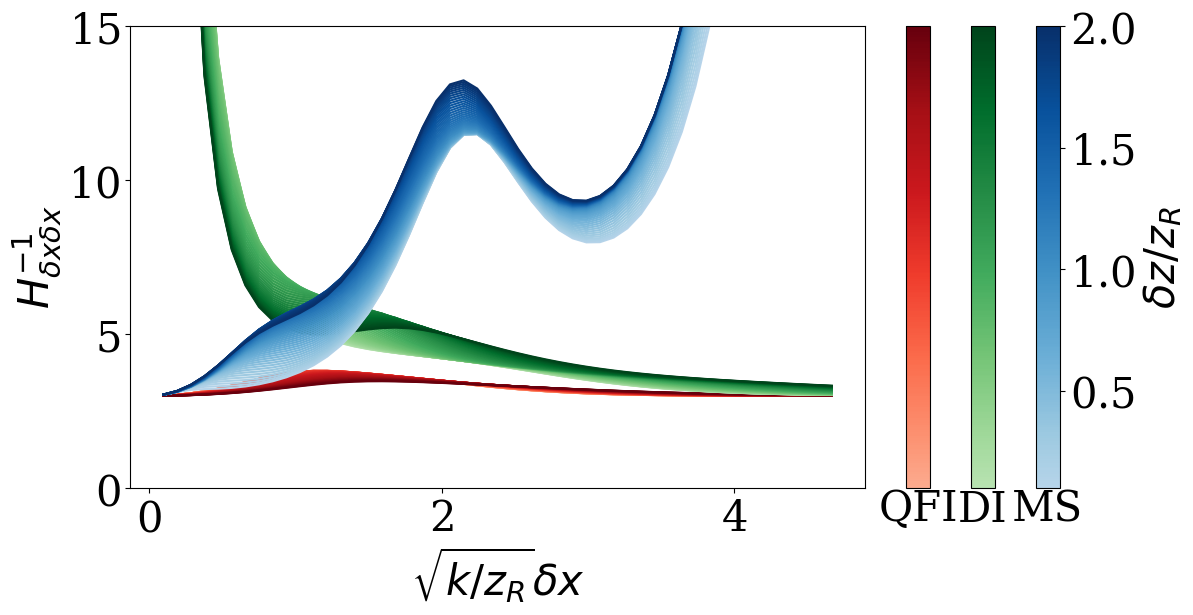

In [18]:
fig, axs = create_fig_and_ax(3)
qfi_cm = plot_individual_fi(
    fig, axs, qfi_inv_[:, :, 0, 0], x_range, p_range, "Reds", 1, "QFI"
)
di_cm = plot_individual_fi(
    fig, axs, fi_di_inv_[:, :, 0, 0], x_range, p_range, "Greens", 2, "DI"
)
ms_cm = plot_individual_fi(
    fig, axs, fi_ms_inv_[:, :, 0, 0], x_range, p_range, "Blues", 3, "MS", False
)

axs[0].set_ylim(0, 15)
axs[3].set_ylabel(r"$\delta z / z_R$")
axs[0].set_xlabel(r"$\sqrt{k/z_R} \delta x$")
axs[0].set_ylabel(r"$H^{-1}_{\delta x \delta x}$")

fig.savefig(f"s_param_covariance.{FORMAT}", format=FORMAT, bbox_inches="tight")
plt.show()

# p param

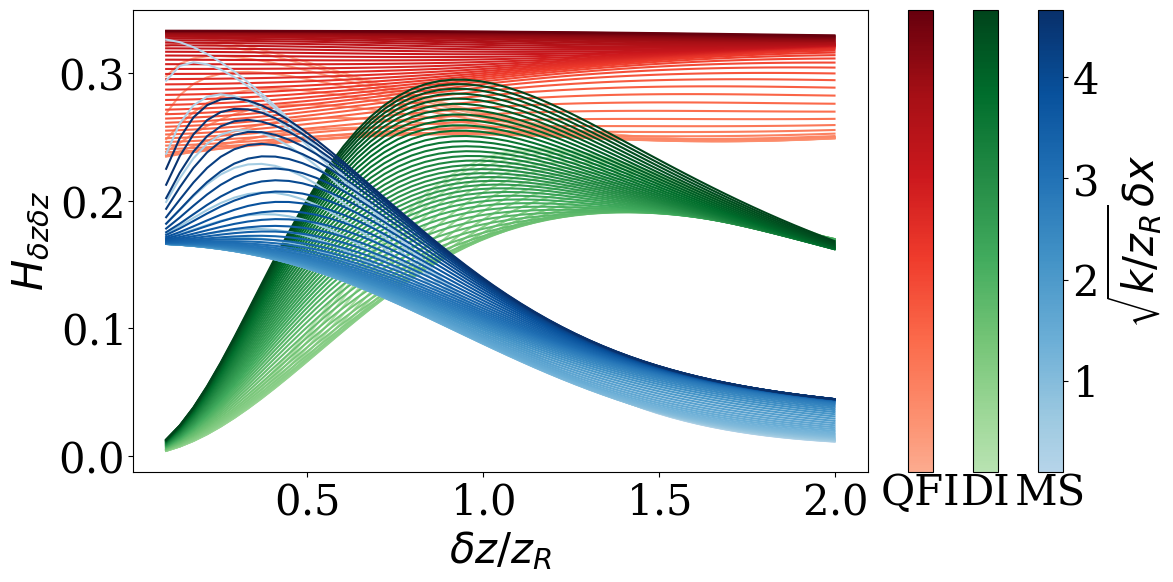

In [19]:
fig, axs = create_fig_and_ax(3)

qfi_cm = plot_individual_fi(
    fig, axs, np.transpose(qfi_[:, :, 1, 1]), p_range, x_range, "Reds", 1, "QFI"
)
di_cm = plot_individual_fi(
    fig, axs, np.transpose(fi_di_[:, :, 1, 1]), p_range, x_range, "Greens", 2, "DI"
)
qfi_cm = plot_individual_fi(
    fig,
    axs,
    np.transpose(np.sum(fi_ms_, axis=2)[:, :, 1, 1]),
    p_range,
    x_range,
    "Blues",
    3,
    "MS",
    False,
)

axs[3].set_ylabel(r"$\sqrt{k/z_R} \delta x$")
axs[0].set_xlabel(r"$\delta z / z_R$")
axs[0].set_ylabel(r"$H_{\delta z \delta z}$")


fig.savefig(f"p_param_fi_comparison.{FORMAT}", format=FORMAT, bbox_inches="tight")

plt.show()

{'x': array([ 0.        , -1.73205081,  0.        ,  1.15470054]), 'y': array([ 0.        , -1.73205081,  0.        ,  1.15470054])}


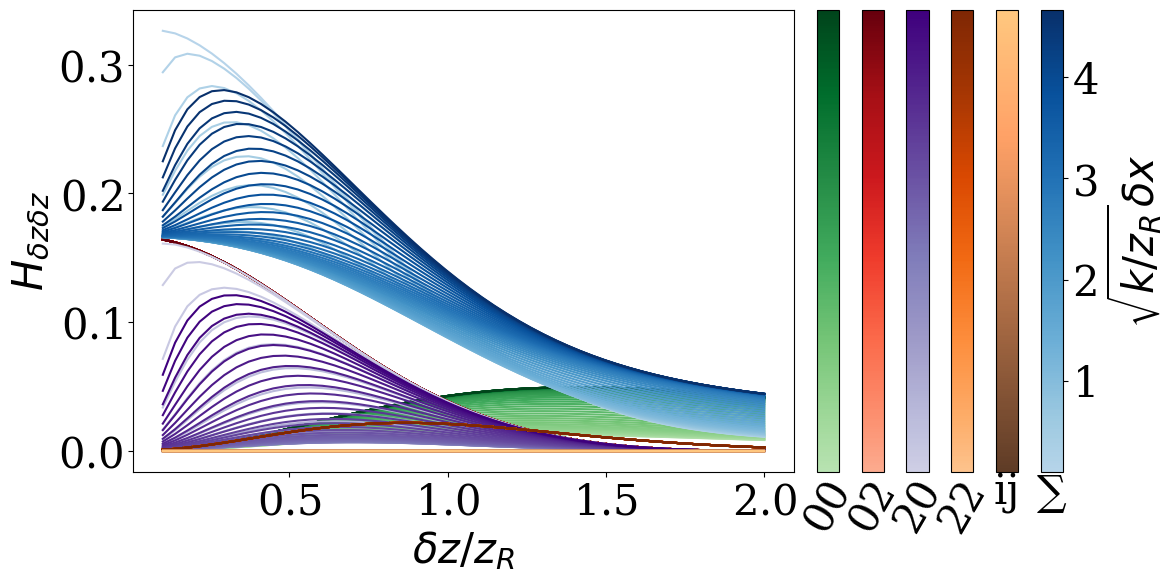

In [ ]:
good_cmaps = filter_pub_friendly_continuous()

n_axes = 5
fig, axs = create_fig_and_ax(n_axes + 1)

counter = 0
for i, j in [(0, 0), (0, 2), (2, 0), (2, 2)]:
    plot_individual_fi(
        fig,
        axs,
        np.transpose(fi_ms_[:, :, i * mode_degree + j, 1, 1]),
        p_range,
        x_range,
        good_cmaps[counter],
        counter + 1,
        f"{i}{j}",
        rotation=60,
    )
    counter += 1

plot_individual_fi(
    fig,
    axs,
    np.transpose(fi_ms_[:, :, 1 * mode_degree + 1, 1, 1]),
    p_range,
    x_range,
    good_cmaps[-2],
    n_axes,
    "ij",
)

plot_individual_fi(
    fig,
    axs,
    np.transpose(np.sum(fi_ms_, axis=2)[:, :, 1, 1]),
    p_range,
    x_range,
    good_cmaps[-1],
    n_axes + 1,
    "∑",
    False,
)


axs[n_axes + 1].set_ylabel(r"$\sqrt{k/z_R} \delta x$")
axs[0].set_xlabel(r"$\delta z / z_R$")
axs[0].set_ylabel(r"$H_{\delta z \delta z}$")

fig.savefig(
    f"p_param_individual_mode_contributions.{FORMAT}",
    format=FORMAT,
    bbox_inches="tight",
)
plt.show()

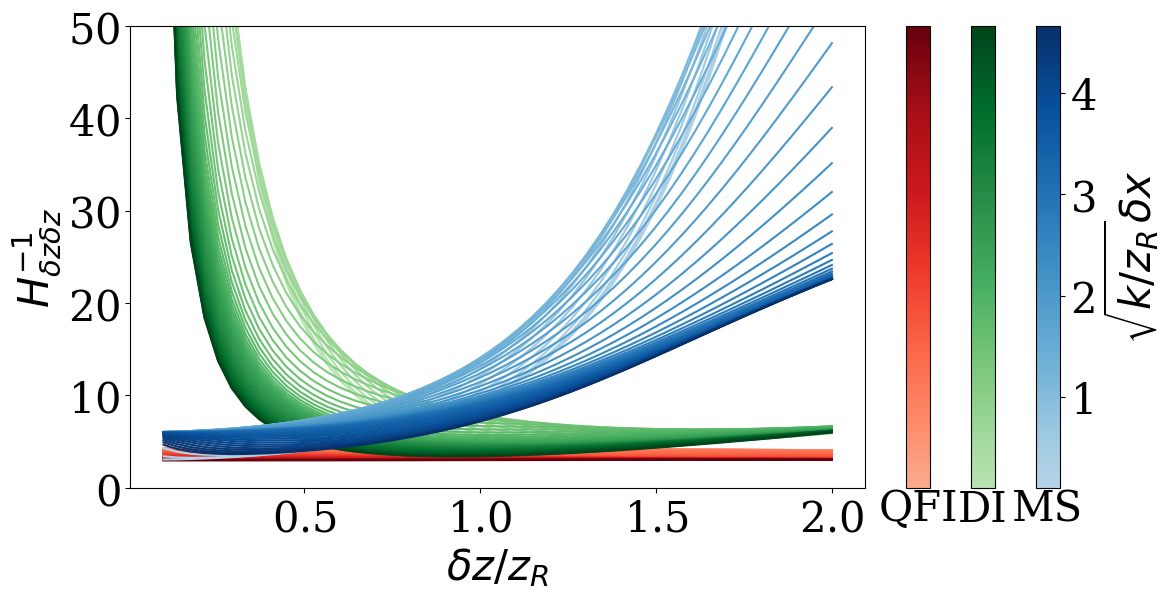

In [21]:
fig, axs = create_fig_and_ax(3)

qfi_cm = plot_individual_fi(
    fig, axs, np.transpose(qfi_inv_[:, :, 1, 1]), p_range, x_range, "Reds", 1, "QFI"
)
di_cm = plot_individual_fi(
    fig, axs, np.transpose(fi_di_inv_[:, :, 1, 1]), p_range, x_range, "Greens", 2, "DI"
)
qfi_cm = plot_individual_fi(
    fig,
    axs,
    np.transpose(fi_ms_inv_[:, :, 1, 1]),
    p_range,
    x_range,
    "Blues",
    3,
    "MS",
    False,
)

axs[0].set_ylim(0, 50)
axs[3].set_ylabel(r"$\sqrt{k/z_R} \delta x$")
axs[0].set_xlabel(r"$\delta z / z_R$")
axs[0].set_ylabel(r"$H^{-1}_{\delta z \delta z}$")

fig.savefig(f"p_param_covariance.{FORMAT}", format=FORMAT, bbox_inches="tight")
plt.show()